## Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa  
        

Levando em conta a base de dados **_Dry Bean Dataset_**, esta segunda parte do Projeto Prático 2.2 diz respeito à proposição e avaliação de múltiplas redes neurais artificiais do tipo Feedforward Multilayer Perceptron para o problema da classificação multiclasse de variedades de feijão seco a partir de características geométricas extraídas de imagens dos grãos.

## Testando Redes Neurais com os Atributos Numéricos

1. Abra a base de dados em questão
2. Verifique que todos os atributos preditores são numéricos. O único atributo categórico é o alvo (`Class`), que não deve entrar em X
3. Armazene o atributo alvo em uma variável y e os atributos preditores em uma variável X
4. Efetue uma partição holdout 70/30 com o sklearn, distribuindo os exemplos de maneira aleatória e estratificada (`stratify=y`), com `random_state` fixo para reprodutibilidade
5. Efetue o escalonamento dos atributos

In [67]:
## Reservado para a importação de bibliotecas
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "ucimlrepo"])
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelBinarizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay

In [55]:
# Constantes
RANDOM_STATE = 42

In [56]:
# 1
dry_bean = fetch_ucirepo(id=602)

In [57]:
# 2
features = dry_bean.data.features
features.dtypes

,0
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRatio,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64


In [58]:
# 3
x = features
y = dry_bean.data.targets

In [59]:
# Não esquecer do one hot encoding dos targets
lb = LabelBinarizer() # one hot para as labels
y = lb.fit_transform(y)
y

array([[0, 0, 0, ..., 0, 1, 0],
       [0, 0, 0, ..., 0, 1, 0],
       [0, 0, 0, ..., 0, 1, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(13611, 7))

In [60]:
# 4
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y
)

### Escalonando os atributos

O treinamento de uma rede neural artificial é mais eficiente quando os valores que lhes são fornecidos como entrada são pequenos e estão em escalas semelhantes, pois isto favorece a convergência. Isto é feito escalonando-se os atributos, mas precisa ser feito de maneira cautelosa, para que informações do conjunto de teste não sejam fornecidas no treinamento.

Há duas estratégias para tal escalonamento: normalização (que leva os valores ao intervalo [0,1]) e padronização (que centraliza os dados em média 0 e desvio padrão 1). Ambas possuem características particulares, vantagens e limitações, como é possível ver aqui: https://www.analyticsvidhya.com/blog/2020/04/feature-scaling-machine-learning-normalization-standardization/

No nosso caso, vamos usar a padronização. Assim, com os atributos preditores do treinamento, isto é, X_train, deve-se subtrair a média e dividir pelo desvio padrão. Para tanto, use o StandardScaler e ajuste-o com os dados do conjunto de treino (fit), transformando-os em seguida (transform). Depois, apenas transforme os dados do conjunto de teste (transform), usando a média e o desvio padrão calculados no treino, sem chamar o fit novamente.

Se todo o conjunto X for utilizado na padronização, a rede neural receberá informações do conjunto de teste por meio da média e do desvio padrão utilizados para preparar os dados de treinamento, o que não é desejável (vazamento de dados, ou *data leakage*).

In [61]:
# 5
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

## Continuando

1. Treine uma rede neural multilayer perceptron para este problema com uma única camada oculta de dez neurônios  
    1.1 Utilize a função de ativação ReLU  
    1.2 Utilize o solver Adam    
    1.3 Imprima o passo a passo do treinamento  
    1.4 Utilize o número máximo de épocas igual a 300
2. Com o modelo em questão, após o treinamento, apresente os resultados para o conjunto de teste:  
    2.1 Matriz de confusão  
    2.2 Acurácia  
    2.3 F-Score (F1)  
    2.4 Precisão  
    2.5 Revocação   
3. Repita o treinamento da mesma rede anterior sem imprimir o passo a passo por 10 vezes  
    3.1 Cada uma destas repetições deve ser feita com uma nova partição holdout 70/30 estratificada, e o escalonamento deve ser reajustado com os dados de treino de cada partição  
    3.2 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
4. Repita por 10 vezes o treinamento desta mesma rede, mas utilizando o otimizador SGD, com as mesmas 10 partições do item anterior  
    4.1 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
5. Houve influência da escolha do otimizador no desempenho da rede? Justifique com as médias e os desvios padrão obtidos

In [62]:
# 1.
clf = MLPClassifier(
    solver="adam",
    activation="relu",
    hidden_layer_sizes=(10,),
    random_state=RANDOM_STATE,
    max_iter=300,
    verbose=True
)

clf.fit(X_train, y_train)

Iteration 1, loss = 5.81573059
Iteration 2, loss = 4.73951192
Iteration 3, loss = 4.00900814
Iteration 4, loss = 3.40216079
Iteration 5, loss = 2.85439350
Iteration 6, loss = 2.38040753
Iteration 7, loss = 2.02409453
Iteration 8, loss = 1.76796950
Iteration 9, loss = 1.58151056
Iteration 10, loss = 1.44061979
Iteration 11, loss = 1.32980518
Iteration 12, loss = 1.23873484
Iteration 13, loss = 1.16228665
Iteration 14, loss = 1.09643106
Iteration 15, loss = 1.03856342
Iteration 16, loss = 0.98742233
Iteration 17, loss = 0.94203946
Iteration 18, loss = 0.90112472
Iteration 19, loss = 0.86389359
Iteration 20, loss = 0.82998358
Iteration 21, loss = 0.79883030
Iteration 22, loss = 0.77026741
Iteration 23, loss = 0.74391315
Iteration 24, loss = 0.71935224
Iteration 25, loss = 0.69672008
Iteration 26, loss = 0.67546629
Iteration 27, loss = 0.65592175
Iteration 28, loss = 0.63752630
Iteration 29, loss = 0.62029341
Iteration 30, loss = 0.60433447
Iteration 31, loss = 0.58913610
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(hidden_layer_sizes=(10,), max_iter=300, random_state=42,
              verbose=True)

In [64]:
# 2.
predictions = clf.predict(X_test)

AttributeError: 'numpy.ndarray' object has no attribute 'figure'

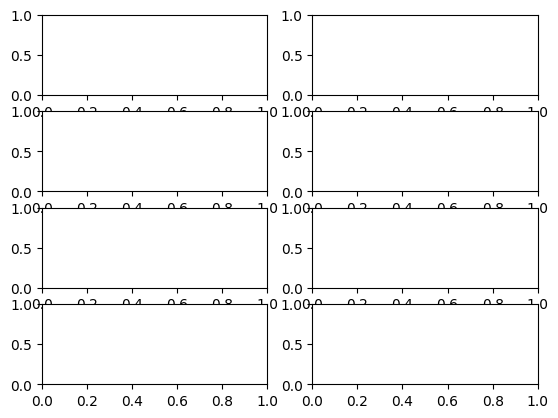

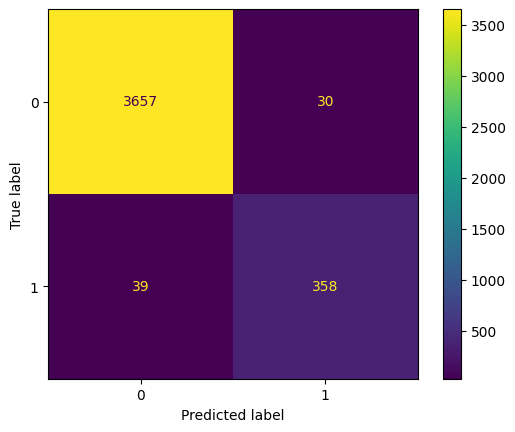

In [75]:
num_labels = 7

fig, axes = plt.subplots(
    4, 2,
    # figsize=(5 * num_labels, 4)
)

# plt.subplots_adjust(wspace = 0.8)
for i, ax in enumerate(axes):
    cm = ConfusionMatrixDisplay.from_predictions(
          y_true=y_test[:, i],
          y_pred=predictions[:, i],
      )
    cm.plot(ax=axes[], cmap="bone")


# logreg_matrix.plot(ax=ax[0], cmap="bone")
# neighbor_matrix.plot(ax=ax[1], cmap="bone")
# tree_matrix.plot(ax=ax[2], cmap="bone")

# font = dict(fontsize=10, fontweight="bold")
# ax[0].set_title("Logistic Regression", **font)
# ax[1].set_title("Nearest Neighbor", **font)
# ax[2].set_title("Decision Tree", **font)

In [71]:
predictions

array([[0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 1, 0, 0],
       [1, 0, 0, ..., 0, 0, 0]], shape=(4084, 7))

ValueError: multilabel-indicator is not supported

## Discussão

Nos passos anteriores, você avaliou o desempenho de uma única arquitetura de rede neural, com uma única camada oculta de 10 neurônios e função de ativação ReLU. O otimizador utilizado, seja o SGD ou o Adam, é o algoritmo que usa o gradiente do erro (calculado pela retropropagação) para atualizar os pesos da rede. Neste sentido, a escolha do otimizador é um hiperparâmetro: ela é definida antes do treinamento, não é aprendida a partir dos dados e controla como a rede será treinada. Também são hiperparâmetros a quantidade de camadas ocultas, o número de neurônios, a função de ativação, a quantidade de épocas, a taxa de aprendizado inicial, dentre outros. Já os parâmetros da rede são os pesos e os vieses, ajustados durante o treinamento.

Cabe salientar também que você efetuou o treinamento desta rede por 10 vezes e apresentou os resultados em termos de média ± desvio padrão. Lembre-se que em uma rede neural há a inicialização aleatória de pesos e, em consequência, o desempenho está sujeito a uma flutuação estocástica. Além disso, cada repetição utilizou uma nova partição holdout, o que introduz uma segunda fonte de variação. A execução múltipla das repetições reduz a influência de uma boa ou má "sorte" na escolha dos pesos iniciais e da partição, que poderia distorcer a conclusão no caso de uma única execução, e permite estimar a variabilidade do desempenho por meio do desvio padrão.

Você também aprendeu uma estratégia para escalonar os atributos para uma melhor convergência da rede. Utilize-a em todos os treinamentos e testes propostos a seguir.

## Propondo Novas Arquiteturas

Variando a arquitetura da rede (uma ou duas camadas ocultas, com diferentes números de neurônios em cada uma delas, e a função de ativação) e os hiperparâmetros solver (Adam ou SGD) e número máximo de épocas (100, 150 e 200), atenda ao que se pede:

1. Proponha 10 arquiteturas distintas de RNAs para o problema em questão, à sua escolha
2. Avalie cada uma das arquiteturas perante todas as combinações de hiperparâmetros (2 solvers × 3 números de épocas), repetindo cada treinamento/avaliação por 10 vezes  
    2.1 Cada repetição deve utilizar uma nova partição holdout 70/30 estratificada, com o escalonamento ajustado apenas com os dados de treino, e as mesmas 10 partições devem ser usadas em todas as configurações, para que a comparação seja justa  
    2.2 Ao todo, serão 60 configurações (10 arquiteturas × 2 solvers × 3 números de épocas) e 600 treinamentos
3. Como resultado da avaliação, apresente, com base no conjunto de teste:  
    3.1 As 3 melhores configurações (arquitetura + solver + número de épocas) no tocante ao F-Score (média macro) e à acurácia, considerando a média das 10 repetições (± desvio padrão)  
    3.2 Para cada uma dessas 3 configurações, a repetição em que houve o melhor desempenho: apresente a matriz de confusão e ilustre, para cada classe, os valores de VP (verdadeiros positivos), VN (verdadeiros negativos), FP (falsos positivos) e FN (falsos negativos)

## Estimando o número de neurônios

Um dos problemas de pesquisa com redes neurais artificiais consiste na determinação do número de neurônios em sua arquitetura. Embora não seja possível definir a priori qual rede neural é adequada para um problema, pois isto só pode ser determinado empiricamente, mediante a avaliação de várias arquiteturas, há regras na literatura que sugerem o número de neurônios escondidos, tal como a regra da Pirâmide Geométrica, dada a seguir:

$$N_h = \alpha \cdot \sqrt{N_i \cdot N_o},$$

em que $N_h$ é o número de neurônios ocultos (a serem distribuídos em uma ou duas camadas ocultas), $N_i$ é o número de neurônios na camada de entrada e $N_o$ é o número de neurônios na camada de saída. Como $N_h$ deve ser um número inteiro, arredonde o resultado para o inteiro mais próximo.

1. Consulte a documentação da classe MLPClassifier (disponível em https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) e obtenha os valores de $N_i$ e $N_o$ para a base _Dry Bean_, considerando o número de atributos preditores e o número de classes do problema.
2. Teste os valores de $\alpha$ como sendo iguais a $0.5$, $2$ e $3$.
3. Proponha pelo menos 30 redes neurais segundo a regra da pirâmide geométrica e teste-as nos mesmos termos estabelecidos anteriormente (solver, épocas, 10 repetições com as mesmas partições holdout, escalonamento, etc.)  
    3.1 Apresente as top-3 melhores redes no tocante à F-Score e Acurácia, com base no conjunto de teste

## Considerações Parciais

1. É possível identificar uma rede com desempenho superior às demais?
2. Qual estratégia mostrou-se mais produtiva para a obtenção de boas arquiteturas (Estratégia Própria ou Pirâmide Geométrica)? Por quê?
3. Um número maior de épocas trouxe melhorias? Justifique com os resultados obtidos, considerando também cada um dos solvers (Adam e SGD)
4. Qual a maior dificuldade de resolução do problema proposto perante as RNAs?